In [14]:
import pandas as pd
import numpy as np

from catboost import CatBoostRegressor

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_pinball_loss
)

import os

In [15]:
df = pd.read_csv("../data/processed/stage2/stage2_df.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (5258, 40)


,title,price,location,ad_url,ad_id,run_id,brand,storage_gb,ram_gb,storage_src,...,title_normalized,title_punct_normalized,title_group,model_key,match_rule,confidence,family,storage_known,ram_known,condition_known
0,Honor Magic V5,80000.0,اوبن اير مول، مدينتي,/ad/honor-magic-v5-ID209010621.html,209010621,legacy,honor,NaN,NaN,NaN,...,honor magic v5,honor magic v5,honor magic v5,honor magic v5,honor:rule_04,NaN,magic,False,False,False
1,شاومي 17 الترا xiaomi 17 ultra,70000.0,التجمع الخامس، القاهرة الجديدة,/ad/%D8%B4%D8%A7%D9%88%D9%85%D9%8A-17-%D8%A7%D...,208281312,legacy,xiaomi,NaN,NaN,NaN,...,شاومي17الترا xiaomi17ultra,شاومي17الترا xiaomi17ultra,شاومي17الترا xiaomi17ultra,xiaomi 17 ultra,xiaomi:rule_17,NaN,xiaomi,False,False,False
2,Apple - iPhone 17 Pro,75000.0,محور 26 يوليو، 6 اكتوبر,/ad/apple-iphone-17-pro-ID208973056.html,208973056,legacy,apple,NaN,NaN,NaN,...,apple iphone17pro,apple iphone17pro,apple iphone17pro,apple iphone 17 pro,apple:model_pattern_06,1.0,iphone,False,False,False
3,Honor 500 pro,35000.0,6 اكتوبر، الجيزة,/ad/honor-500-pro-ID208029599.html,208029599,legacy,honor,NaN,NaN,NaN,...,honor500pro,honor500pro,honor500pro,honor 500 pro,honor:rule_07,NaN,honor numeric,False,False,False
4,آبل - آيفون 15 برو ماكس,58000.0,ستيلا هليوبوليس، مدينة الشروق,/ad/%D8%A2%D8%A8%D9%84-%D8%A2%D9%8A%D9%81%D9%8...,208989761,legacy,apple,NaN,NaN,NaN,...,ابل ايفون15برو ماكس,ابل ايفون15برو ماكس,ابل ايفون15برو ماكس,apple iphone 15 pro max,apple:model_pattern_02,1.0,iphone,False,False,False


In [16]:
# Check dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5258 entries, 0 to 5257
Data columns (total 40 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   title                   5258 non-null   str    
 1   price                   5258 non-null   float64
 2   location                5254 non-null   str    
 3   ad_url                  5258 non-null   str    
 4   ad_id                   5258 non-null   int64  
 5   run_id                  5258 non-null   str    
 6   brand                   4979 non-null   str    
 7   storage_gb              367 non-null    float64
 8   ram_gb                  112 non-null    float64
 9   storage_src             367 non-null    str    
 10  condition               283 non-null    str    
 11  condition_src           283 non-null    str    
 12  ram_src                 112 non-null    str    
 13  has_5g                  5258 non-null   bool   
 14  has_warranty            5258 non-null   bool   
 15

In [17]:
# Check target distribution
print("Missing Prices:", df['price'].isnull().sum())

print("\nPrice Statistics:")
print(df['price'].describe())

print("\nNumber of Unique Prices:")
print(df['price'].nunique())

Missing Prices: 0

Price Statistics:
count      5258.000000
mean      22858.786421
std       20722.258158
min        1000.000000
25%        7000.000000
50%       16500.000000
75%       32000.000000
max      185500.000000
Name: price, dtype: float64

Number of Unique Prices:
416


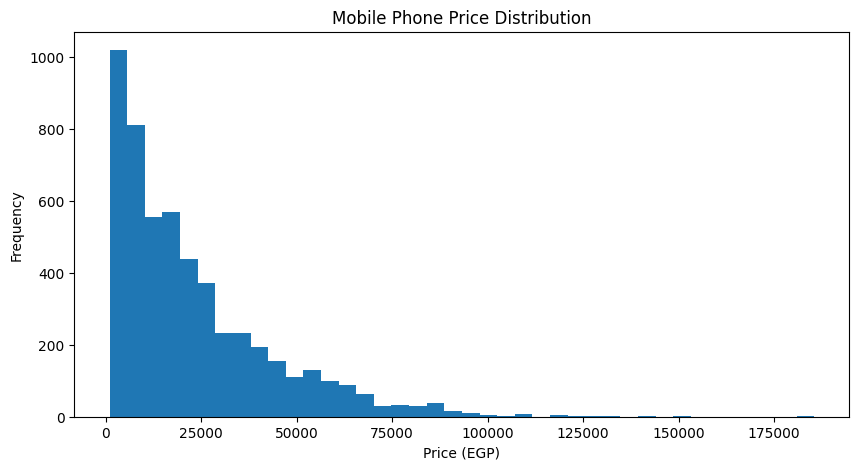

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df['price'], bins=40)

plt.title('Mobile Phone Price Distribution')
plt.xlabel('Price (EGP)')
plt.ylabel('Frequency')

plt.show()

In [19]:
print("Duplicate ad_id:", df['ad_id'].duplicated().sum())

print("Duplicate title_group:", df['title_group'].duplicated().sum())

Duplicate ad_id: 0
Duplicate title_group: 3067


In [20]:
print("Total Ads:", len(df))

print("Unique Model Groups:", df['title_group'].nunique())

print("Unique Model Keys:", df['model_key'].nunique())

print("Unique Families:", df['family'].nunique())

Total Ads: 5258
Unique Model Groups: 2191
Unique Model Keys: 728
Unique Families: 67


In [21]:
features = [
    'model_key',
    'brand',
    'family',
    'storage_gb',
    'ram_gb',
    'condition',
    'has_5g',
    'has_warranty',
    'has_box',
    'mentions_exchange',
    'is_wanted_ad',
    'is_accessory_hint',
    'is_tablet_hint',
    'is_parts_hint',
    'accessory_first',
    'bundle_hint',
    'is_feature_phone_hint',
    'loc_area',
    'loc_city',
    'storage_known',
    'ram_known',
    'condition_known'
]

target = 'price'

X = df[features].copy()
y = df[target].copy()

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nCategorical Features:")
cat_features = X.select_dtypes(include=['str', 'object']).columns.tolist()

print(cat_features)

Features Shape: (5258, 22)
Target Shape: (5258,)

Categorical Features:
['model_key', 'brand', 'family', 'condition', 'loc_area', 'loc_city']


In [22]:
print("Missing Values in Features:")
print(X.isnull().sum().sort_values(ascending=False))

Missing Values in Features:
ram_gb                   5146
condition                4975
storage_gb               4891
brand                     279
loc_area                    4
loc_city                    4
family                      0
model_key                   0
has_5g                      0
has_warranty                0
is_wanted_ad                0
is_accessory_hint           0
has_box                     0
mentions_exchange           0
is_parts_hint               0
is_tablet_hint              0
bundle_hint                 0
accessory_first             0
is_feature_phone_hint       0
storage_known               0
ram_known                   0
condition_known             0
dtype: int64


In [23]:
# Identify categorical features
cat_features = X.select_dtypes(include=['str', 'object']).columns.tolist()

# Handle missing categorical values
for col in cat_features:
    X[col] = X[col].fillna('Unknown').astype(str)

# Verify
print("Missing values in categorical features:")
print(X[cat_features].isnull().sum())

print("\nCategorical features:")
print(cat_features)

Missing values in categorical features:
model_key    0
brand        0
family       0
condition    0
loc_area     0
loc_city     0
dtype: int64

Categorical features:
['model_key', 'brand', 'family', 'condition', 'loc_area', 'loc_city']


In [24]:
# First split: 70% Train, 30% Temporary
gss1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    gss1.split(X, y, groups=df['title_group'])
)

# Second split: 15% Validation, 15% Test
gss2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss2.split(
        X.iloc[temp_idx],
        y.iloc[temp_idx],
        groups=df['title_group'].iloc[temp_idx]
    )
)

# Create datasets
X_train = X.iloc[train_idx].copy()
X_val = X.iloc[temp_idx[val_idx]].copy()
X_test = X.iloc[temp_idx[test_idx]].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[temp_idx[val_idx]].copy()
y_test = y.iloc[temp_idx[test_idx]].copy()

# Check shapes
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (3576, 22) (3576,)
Validation: (736, 22) (736,)
Test: (946, 22) (946,)


In [25]:
train_groups = set(df.iloc[train_idx]['title_group'])
val_groups = set(df.iloc[temp_idx[val_idx]]['title_group'])
test_groups = set(df.iloc[temp_idx[test_idx]]['title_group'])

print("Train & Validation overlap:", len(train_groups & val_groups))

print("Train & Test overlap:", len(train_groups & test_groups))

print("Validation & Test overlap:", len(val_groups & test_groups))

Train & Validation overlap: 0
Train & Test overlap: 0
Validation & Test overlap: 0


In [26]:
catboost_params = {
    'iterations': 1500,
    'learning_rate': 0.03,
    'depth': 6,
    'eval_metric': 'MAE',
    'random_seed': 42,
    'verbose': 100,
    'allow_writing_files': False
}

In [27]:
print(catboost_params)

{'iterations': 1500, 'learning_rate': 0.03, 'depth': 6, 'eval_metric': 'MAE', 'random_seed': 42, 'verbose': 100, 'allow_writing_files': False}


In [28]:
model_p10 = CatBoostRegressor(
    **catboost_params,
    loss_function='Quantile:alpha=0.1'
)

model_p10.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100
)

0:	learn: 20234.7024633	test: 19582.8546207	best: 19582.8546207 (0)	total: 167ms	remaining: 4m 10s
100:	learn: 13468.5173848	test: 15026.8550977	best: 15026.8550977 (100)	total: 4.38s	remaining: 1m
200:	learn: 12535.1013574	test: 14492.6242670	best: 14492.6242670 (200)	total: 8.63s	remaining: 55.7s
300:	learn: 12200.4719041	test: 14361.5529610	best: 14361.5529610 (300)	total: 12.4s	remaining: 49.6s
400:	learn: 12001.1098213	test: 14387.1563717	best: 14361.5529610 (300)	total: 16.2s	remaining: 44.5s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 14361.55296
bestIteration = 300

Shrink model to first 301 iterations.


CatBoostRegressor(allow_writing_files=False, depth=6, eval_metric='MAE', iterations=1500, learning_rate=0.03, loss_function='Quantile:alpha=0.1', random_seed=42, verbose=100)

In [29]:
model_p50 = CatBoostRegressor(
    **catboost_params,
    loss_function='Quantile:alpha=0.5'
)

model_p50.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100
)

0:	learn: 15377.7967057	test: 15696.2038074	best: 15696.2038074 (0)	total: 79.5ms	remaining: 1m 59s
100:	learn: 8544.6911530	test: 12243.2744993	best: 12227.1670928 (98)	total: 4.21s	remaining: 58.3s
200:	learn: 7983.0301717	test: 12152.4266612	best: 12139.2716756 (198)	total: 8.33s	remaining: 53.8s
300:	learn: 7601.6288460	test: 11930.8110605	best: 11923.9622634 (274)	total: 12.5s	remaining: 49.7s
400:	learn: 7335.7441231	test: 11896.0613205	best: 11896.0613205 (400)	total: 16.4s	remaining: 44.9s
500:	learn: 7126.3977594	test: 11939.6916603	best: 11893.7630422 (402)	total: 20.4s	remaining: 40.7s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 11893.76304
bestIteration = 402

Shrink model to first 403 iterations.


CatBoostRegressor(allow_writing_files=False, depth=6, eval_metric='MAE', iterations=1500, learning_rate=0.03, loss_function='Quantile:alpha=0.5', random_seed=42, verbose=100)

In [30]:
model_p90 = CatBoostRegressor(
    **catboost_params,
    loss_function='Quantile:alpha=0.9'
)

model_p90.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100
)

0:	learn: 34169.3959845	test: 34228.3410445	best: 34228.3410445 (0)	total: 41.3ms	remaining: 1m 1s
100:	learn: 15902.8835846	test: 18291.6473493	best: 18291.6473493 (100)	total: 4.3s	remaining: 59.5s
200:	learn: 14381.6490343	test: 17300.1356589	best: 17300.1356589 (200)	total: 8.08s	remaining: 52.2s
300:	learn: 13889.9113799	test: 17071.6866031	best: 17071.6866031 (300)	total: 11.9s	remaining: 47.4s
400:	learn: 13474.2254601	test: 16874.7043636	best: 16861.5634648 (391)	total: 15.8s	remaining: 43.2s
500:	learn: 13212.5488067	test: 16684.9267132	best: 16684.9267132 (500)	total: 19.7s	remaining: 39.3s
600:	learn: 12987.1704192	test: 16536.5148729	best: 16536.5148729 (600)	total: 23.6s	remaining: 35.4s
700:	learn: 12824.9718905	test: 16445.2935726	best: 16445.2935726 (700)	total: 27.7s	remaining: 31.5s
800:	learn: 12683.4146086	test: 16365.4208405	best: 16364.9871969 (799)	total: 31.4s	remaining: 27.4s
900:	learn: 12554.5853729	test: 16325.3732741	best: 16325.3732741 (900)	total: 35.5s	r

CatBoostRegressor(allow_writing_files=False, depth=6, eval_metric='MAE', iterations=1500, learning_rate=0.03, loss_function='Quantile:alpha=0.9', random_seed=42, verbose=100)

In [31]:
# Generate predictions on test data

pred_p10 = model_p10.predict(X_test)
pred_p50 = model_p50.predict(X_test)
pred_p90 = model_p90.predict(X_test)

# Create prediction dataframe

predictions = pd.DataFrame({
    'Actual_Price': y_test.values,
    'P10': pred_p10,
    'P50': pred_p50,
    'P90': pred_p90
})

predictions.head(10)

,Actual_Price,P10,P50,P90
0,65000.0,28137.018953,52601.490886,66797.169888
1,89000.0,30954.349791,70373.389582,98897.529867
2,66000.0,29970.409758,55972.130738,74315.461211
3,15000.0,12022.688174,16764.775933,22601.609860
4,5500.0,3758.255109,8050.923617,11868.492710
5,9500.0,3851.678652,9621.452436,12028.530557
6,68000.0,3509.939562,16847.386721,52131.339510
7,51000.0,21502.199155,37108.490213,38853.272072
8,26000.0,17661.551796,23177.861203,30117.989879
9,27500.0,21714.577579,36865.744876,94751.008614


In [32]:
# Check quantile crossing

crossing_p10_p50 = (predictions['P10'] > predictions['P50']).sum()

crossing_p50_p90 = (predictions['P50'] > predictions['P90']).sum()

crossing_total = (
    (predictions['P10'] > predictions['P50']) |
    (predictions['P50'] > predictions['P90'])
).sum()

print("P10 > P50:", crossing_p10_p50)
print("P50 > P90:", crossing_p50_p90)
print("Total Crossing Cases:", crossing_total)

print("Total Test Samples:", len(predictions))

P10 > P50: 0
P50 > P90: 9
Total Crossing Cases: 9
Total Test Samples: 946


In [33]:
# Apply quantile ordering

quantile_values = predictions[['P10', 'P50', 'P90']].values

quantile_values_sorted = np.sort(quantile_values, axis=1)

predictions[['P10', 'P50', 'P90']] = quantile_values_sorted

# Verify ordering

print(
    "Remaining Crossing Cases:",
    (
        (predictions['P10'] > predictions['P50']) |
        (predictions['P50'] > predictions['P90'])
    ).sum()
)

Remaining Crossing Cases: 0


In [34]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_pinball_loss
)

# Actual prices
y_true = predictions['Actual_Price']

# P50 evaluation
mae = mean_absolute_error(y_true, predictions['P50'])

rmse = np.sqrt(
    mean_squared_error(y_true, predictions['P50'])
)

r2 = r2_score(y_true, predictions['P50'])

# Quantile evaluation
pinball_p10 = mean_pinball_loss(
    y_true, predictions['P10'], alpha=0.1
)

pinball_p50 = mean_pinball_loss(
    y_true, predictions['P50'], alpha=0.5
)

pinball_p90 = mean_pinball_loss(
    y_true, predictions['P90'], alpha=0.9
)

# Prediction interval evaluation
coverage = (
    (y_true >= predictions['P10']) &
    (y_true <= predictions['P90'])
).mean() * 100

average_width = (
    predictions['P90'] - predictions['P10']
).mean()

# Display results
print("===== P50 Metrics =====")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")

print("\n===== Quantile Metrics =====")
print(f"P10 Pinball Loss: {pinball_p10:.2f}")
print(f"P50 Pinball Loss: {pinball_p50:.2f}")
print(f"P90 Pinball Loss: {pinball_p90:.2f}")

print("\n===== Prediction Interval Metrics =====")
print(f"Coverage: {coverage:.2f}%")
print(f"Average Interval Width: {average_width:.2f} EGP")

===== P50 Metrics =====
MAE: 7329.65
RMSE: 13051.48
R2 Score: 0.4451

===== Quantile Metrics =====
P10 Pinball Loss: 1222.46
P50 Pinball Loss: 3664.82
P90 Pinball Loss: 2556.60

===== Prediction Interval Metrics =====
Coverage: 68.82%
Average Interval Width: 22523.37 EGP


In [35]:
# Calculate prediction errors

predictions['Absolute_Error'] = abs(
    predictions['Actual_Price'] - predictions['P50']
)

predictions['Interval_Width'] = (
    predictions['P90'] - predictions['P10']
)

# Sort by largest prediction errors

worst_predictions = predictions.sort_values(
    by='Absolute_Error',
    ascending=False
)

print("Average Absolute Error:", predictions['Absolute_Error'].mean())

print("\nWorst 10 Predictions:")
display(worst_predictions.head(10))

Average Absolute Error: 7329.64526391459

Worst 10 Predictions:


,Actual_Price,P10,P50,P90,Absolute_Error,Interval_Width
113,185500.0,2773.005895,11905.060369,36174.943369,173594.939631,33401.937474
323,120000.0,1922.859199,10659.371718,54364.684745,109340.628282,52441.825546
242,100000.0,2615.369147,7575.050365,17887.337282,92424.949635,15271.968135
611,86000.0,1828.486686,10181.603815,36497.231429,75818.396185,34668.744743
943,85000.0,2019.480952,10083.737387,34349.188348,74916.262613,32329.707396
170,88000.0,3314.138759,19096.555816,51565.541375,68903.444184,48251.402616
288,80000.0,2582.523832,12365.256031,45673.709763,67634.743969,43091.185931
259,79999.0,3216.519159,16986.347318,50041.092942,63012.652682,46824.573783
708,62000.0,2000.582984,10617.009417,35810.754665,51382.990583,33810.171682
6,68000.0,3509.939562,16847.386721,52131.339510,51152.613279,48621.399948


In [36]:
worst_predictions[
    ['Actual_Price', 'P10', 'P50', 'P90',
     'Absolute_Error', 'Interval_Width']
].head(10).round(2)

,Actual_Price,P10,P50,P90,Absolute_Error,Interval_Width
113,185500.0,2773.01,11905.06,36174.94,173594.94,33401.94
323,120000.0,1922.86,10659.37,54364.68,109340.63,52441.83
242,100000.0,2615.37,7575.05,17887.34,92424.95,15271.97
611,86000.0,1828.49,10181.60,36497.23,75818.40,34668.74
943,85000.0,2019.48,10083.74,34349.19,74916.26,32329.71
170,88000.0,3314.14,19096.56,51565.54,68903.44,48251.40
288,80000.0,2582.52,12365.26,45673.71,67634.74,43091.19
259,79999.0,3216.52,16986.35,50041.09,63012.65,46824.57
708,62000.0,2000.58,10617.01,35810.75,51382.99,33810.17
6,68000.0,3509.94,16847.39,52131.34,51152.61,48621.40


In [37]:
price_bins = [0, 10000, 20000, 40000, 60000, 100000, float('inf')]
price_labels = [
    'Under 10K',
    '10K - 20K',
    '20K - 40K',
    '40K - 60K',
    '60K - 100K',
    'Above 100K'
]

train_price_distribution = pd.cut(
    y_train,
    bins=price_bins,
    labels=price_labels
).value_counts().sort_index()

test_price_distribution = pd.cut(
    y_test,
    bins=price_bins,
    labels=price_labels
).value_counts().sort_index()

distribution = pd.DataFrame({
    'Train_Count': train_price_distribution,
    'Train_Percentage': (train_price_distribution / len(y_train) * 100).round(2),
    'Test_Count': test_price_distribution,
    'Test_Percentage': (test_price_distribution / len(y_test) * 100).round(2)
})

display(distribution)

,Train_Count,Train_Percentage,Test_Count,Test_Percentage
price,,,,
Under 10K,1223,34.20,328,34.67
10K - 20K,840,23.49,271,28.65
20K - 40K,847,23.69,242,25.58
40K - 60K,406,11.35,74,7.82
60K - 100K,241,6.74,29,3.07
Above 100K,19,0.53,2,0.21


In [38]:
predictions['Price_Range'] = pd.cut(
    predictions['Actual_Price'],
    bins=price_bins,
    labels=price_labels
)

error_by_range = predictions.groupby(
    'Price_Range',
    observed=False
).agg(
    Count=('Absolute_Error', 'count'),
    MAE=('Absolute_Error', 'mean'),
    Average_Actual=('Actual_Price', 'mean'),
    Average_Predicted=('P50', 'mean')
).round(2)

display(error_by_range)

,Count,MAE,Average_Actual,Average_Predicted
Price_Range,,,,
Under 10K,328,4067.73,5691.01,8057.72
10K - 20K,271,6660.72,15244.80,15614.47
20K - 40K,242,7136.64,26768.59,26759.11
40K - 60K,74,10655.69,50472.93,40623.55
60K - 100K,29,34346.53,73703.41,39356.88
Above 100K,2,141467.78,152750.00,11282.22


In [39]:
# Transform target
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)

# Train P50 model with log-transformed target
model_v2_p50 = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.03,
    depth=6,
    loss_function='Quantile:alpha=0.5',
    eval_metric='Quantile:alpha=0.5',
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

model_v2_p50.fit(
    X_train,
    y_train_log,
    cat_features=cat_features,
    eval_set=(X_val, y_val_log),
    early_stopping_rounds=100
)

0:	learn: 0.4107249	test: 0.4464082	best: 0.4464082 (0)	total: 34.2ms	remaining: 51.3s
100:	learn: 0.2287914	test: 0.3588071	best: 0.3585745 (90)	total: 4.36s	remaining: 1m
200:	learn: 0.2167186	test: 0.3550727	best: 0.3547050 (188)	total: 8.54s	remaining: 55.2s
300:	learn: 0.2092805	test: 0.3543779	best: 0.3543779 (300)	total: 12.8s	remaining: 51.1s
400:	learn: 0.2022537	test: 0.3533396	best: 0.3530623 (354)	total: 17.1s	remaining: 46.7s
500:	learn: 0.1967872	test: 0.3532217	best: 0.3530330 (416)	total: 21.1s	remaining: 42.2s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.3530330056
bestIteration = 416

Shrink model to first 417 iterations.


CatBoostRegressor(allow_writing_files=False, depth=6, eval_metric='Quantile:alpha=0.5', iterations=1500, learning_rate=0.03, loss_function='Quantile:alpha=0.5', random_seed=42, verbose=100)

In [40]:
# Predict on test set
pred_v2_log = model_v2_p50.predict(X_test)

# Convert predictions back to original price scale
pred_v2_p50 = np.expm1(pred_v2_log)

# Calculate metrics
v2_mae = mean_absolute_error(y_test, pred_v2_p50)
v2_rmse = np.sqrt(mean_squared_error(y_test, pred_v2_p50))
v2_r2 = r2_score(y_test, pred_v2_p50)

print(f"V2 P50 MAE: {v2_mae:.2f} EGP")
print(f"V2 P50 RMSE: {v2_rmse:.2f} EGP")
print(f"V2 P50 R2: {v2_r2:.4f}")

V2 P50 MAE: 7217.23 EGP
V2 P50 RMSE: 12984.65 EGP
V2 P50 R2: 0.4508


In [41]:
v2_analysis = pd.DataFrame({
    'Actual_Price': y_test.values,
    'V2_Predicted': pred_v2_p50
})

v2_analysis['Price_Range'] = pd.cut(
    v2_analysis['Actual_Price'],
    bins=price_bins,
    labels=price_labels
)

v2_error_by_range = v2_analysis.groupby(
    'Price_Range',
    observed=False
).agg(
    Count=('Actual_Price', 'count'),
    MAE=('V2_Predicted', lambda x: np.mean(
        np.abs(x - v2_analysis.loc[x.index, 'Actual_Price'])
    )),
    Average_Actual=('Actual_Price', 'mean'),
    Average_Predicted=('V2_Predicted', 'mean')
).round(2)

display(v2_error_by_range)

,Count,MAE,Average_Actual,Average_Predicted
Price_Range,,,,
Under 10K,328,4008.85,5691.01,8167.08
10K - 20K,271,6527.98,15244.80,15696.98
20K - 40K,242,7111.01,26768.59,26582.07
40K - 60K,74,10443.24,50472.93,41290.70
60K - 100K,29,33328.74,73703.41,40374.68
Above 100K,2,141658.59,152750.00,11091.41


In [42]:
# Calculate sample weights using training prices
sample_weights = np.sqrt(
    y_train / y_train.median()
)

# Limit extreme weights
sample_weights = np.clip(
    sample_weights,
    0.5,
    3.0
)

print("Weight Statistics:")
print(sample_weights.describe().round(3))

Weight Statistics:
count    3576.000
mean        1.080
std         0.487
min         0.500
25%         0.651
50%         1.000
75%         1.414
max         2.970
Name: price, dtype: float64


In [43]:
model_v3_p50 = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.03,
    depth=6,
    loss_function='Quantile:alpha=0.5',
    eval_metric='Quantile:alpha=0.5',
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

model_v3_p50.fit(
    X_train,
    y_train_log,
    cat_features=cat_features,
    sample_weight=sample_weights,
    eval_set=(X_val, y_val_log),
    early_stopping_rounds=100
)

0:	learn: 0.3625764	test: 0.4783088	best: 0.4783088 (0)	total: 44.1ms	remaining: 1m 6s
100:	learn: 0.2114070	test: 0.3536996	best: 0.3534836 (88)	total: 4.32s	remaining: 59.8s
200:	learn: 0.1988906	test: 0.3520836	best: 0.3520652 (154)	total: 8.84s	remaining: 57.1s
300:	learn: 0.1893220	test: 0.3505374	best: 0.3505248 (291)	total: 13.4s	remaining: 53.3s
400:	learn: 0.1822174	test: 0.3496663	best: 0.3494842 (374)	total: 18.4s	remaining: 50.5s
500:	learn: 0.1767563	test: 0.3485088	best: 0.3484913 (498)	total: 25.4s	remaining: 50.6s
600:	learn: 0.1723525	test: 0.3472861	best: 0.3472614 (598)	total: 32.5s	remaining: 48.6s
700:	learn: 0.1685846	test: 0.3466848	best: 0.3466248 (697)	total: 39.3s	remaining: 44.7s
800:	learn: 0.1655306	test: 0.3466865	best: 0.3464100 (784)	total: 46s	remaining: 40.1s
900:	learn: 0.1620706	test: 0.3462909	best: 0.3462116 (890)	total: 52.5s	remaining: 34.9s
1000:	learn: 0.1589019	test: 0.3460037	best: 0.3456778 (963)	total: 58.9s	remaining: 29.4s
Stopped by over

CatBoostRegressor(allow_writing_files=False, depth=6, eval_metric='Quantile:alpha=0.5', iterations=1500, learning_rate=0.03, loss_function='Quantile:alpha=0.5', random_seed=42, verbose=100)

In [44]:
# Predict on test set
pred_v3_log = model_v3_p50.predict(X_test)

# Convert back to EGP
pred_v3_p50 = np.expm1(pred_v3_log)

# Calculate metrics
v3_mae = mean_absolute_error(y_test, pred_v3_p50)
v3_rmse = np.sqrt(mean_squared_error(y_test, pred_v3_p50))
v3_r2 = r2_score(y_test, pred_v3_p50)

print(f"V3 P50 MAE: {v3_mae:.2f} EGP")
print(f"V3 P50 RMSE: {v3_rmse:.2f} EGP")
print(f"V3 P50 R2: {v3_r2:.4f}")

V3 P50 MAE: 7405.05 EGP
V3 P50 RMSE: 13316.13 EGP
V3 P50 R2: 0.4224


In [45]:
comparison = pd.DataFrame({
    'Model': ['V1 - Original', 'V2 - Log', 'V3 - Log + Weights'],
    'MAE': [7329.65, v2_mae, v3_mae],
    'RMSE': [13051.48, v2_rmse, v3_rmse],
    'R2': [0.4451, v2_r2, v3_r2]
})

display(comparison.round(4))

,Model,MAE,RMSE,R2
0,V1 - Original,7329.6500,13051.4800,0.4451
1,V2 - Log,7217.2311,12984.6508,0.4508
2,V3 - Log + Weights,7405.0454,13316.1328,0.4224


In [46]:
import os
import joblib

# Create model output directory
os.makedirs("../models/catboost_v2", exist_ok=True)

# Save V2 model
model_v2_p50.save_model(
    "../models/catboost_v2/model_v2_p50.cbm"
)

# Save test predictions
v2_results = pd.DataFrame({
    'Actual_Price': y_test.values,
    'Predicted_P50': pred_v2_p50
})

v2_results.to_csv(
    "../models/catboost_v2/v2_test_predictions.csv",
    index=False
)

# Save comparison metrics
comparison.to_csv(
    "../models/catboost_v2/model_comparison.csv",
    index=False
)

print("V2 model and evaluation results saved successfully!")

V2 model and evaluation results saved successfully!
